# 05 · Evaluation metrics and baselines

**Data science step 5 of 7:** decide **how to measure** a prediction, and set the bar that any ML model must beat.

**Input:** `examples_dev.parquet` (from notebook 04)
**Everything here is measured on the *valid* split (Sept 21–25).** The test split is saved for notebook 07.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("data/processed")
FIGURES = Path("reports/figures")

dev = pd.read_parquet(DATA / "examples_dev.parquet")
valid = dev[dev["split"] == "valid"]
y_valid = valid["target"].to_numpy()
print(f"valid: {len(valid):,} examples")

valid: 182,384 examples


## Step 1: Evaluation metrics

We predict a number of minutes, so this is a **regression** problem. Each metric answers a different question:

| Metric | Question it answers | Formula |
|---|---|---|
| **MAE** (mean absolute error) | On average, how many minutes off are we? **Our headline metric.** | mean of \|prediction − actual\| |
| **MedianAE** | How far off is a *typical* prediction? | median of \|prediction − actual\| |
| **RMSE** (root mean squared error) | Same as MAE, but **big misses count much more** | √ mean of (prediction − actual)² |
| **R²** | What share of the variation do we explain? 1 = perfect, 0 = no better than always guessing the average | 1 − SSE / SST |
| **within 10 / 30 min** | How often are we "close enough" for a passenger? | % with \|error\| ≤ 10 (or 30) |
| **bias** | Do we predict too early or too late on average? | mean of (prediction − actual) |

**Why MAE as the headline?** It's in minutes, so anyone can understand it ("off by 15 minutes on average"), and a few 30-hour delays don't dominate it the way they dominate RMSE.

In [2]:
def evaluate(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    error = y_pred - y_true
    return {
        "MAE": np.mean(np.abs(error)),
        "MedianAE": np.median(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "R2": 1 - np.sum(error ** 2) / np.sum((y_true - y_true.mean()) ** 2),
        "within_10min_%": 100 * np.mean(np.abs(error) <= 10),
        "within_30min_%": 100 * np.mean(np.abs(error) <= 30),
        "bias": np.mean(error),
    }


# Tiny example to see the metrics work: 4 trains, real vs predicted delay
evaluate(y_true=[0, 10, 30, 120], y_pred=[5, 10, 20, 60])

{'MAE': np.float64(18.75),
 'MedianAE': np.float64(7.5),
 'RMSE': np.float64(30.516389039334257),
 'R2': np.float64(0.5861111111111111),
 'within_10min_%': np.float64(75.0),
 'within_30min_%': np.float64(75.0),
 'bias': np.float64(-16.25)}

Check by hand: errors are 5, 0, 10, 60 → **MAE** = 75 / 4 = 18.75 ✅. One big miss (60) pushes **RMSE** up to 30.5. 3 of 4 predictions are within 10 minutes (errors 5, 0, 10) → **75%** ✅.

## Step 2: Baselines (simple rules, no ML)

A model is only useful if it beats simple rules. Three of them:

1. **Zero:** every train arrives on time
2. **Persistence:** the delay stays exactly as it is now
3. **Historical:** current delay + this train's usual change from this station to the destination (`hist_change`)

In [3]:
baselines = {
    "Zero": np.zeros(len(valid)),
    "Persistence": valid["cur_delay"].to_numpy(),
    "Historical": np.clip(valid["cur_delay"] + valid["hist_change"].fillna(0), 0, None).to_numpy(),
}

results = pd.DataFrame({name: evaluate(y_valid, pred) for name, pred in baselines.items()}).T
results.sort_values("MAE").round(2)

,MAE,MedianAE,RMSE,R2,within_10min_%,within_30min_%,bias
Historical,18.02,4.0,48.16,0.71,66.15,85.21,-0.42
Persistence,23.61,9.0,56.03,0.61,53.65,79.54,-1.25
Zero,28.78,0.0,94.05,-0.10,75.83,83.90,-28.78


### Reading the table
- **Historical is clearly the best** (MAE ≈ 18 min). Knowing *this train's* usual behaviour from *this station* is very powerful.
- ⚠️ **Zero** has the best *within 10 min* (76%) because most trains really do arrive on time, but the **worst MAE**: it's badly wrong for every late train. **Never judge a model on one metric.**
- **R² of Zero is slightly negative:** guessing 0 for everyone is worse than guessing the average for everyone.

## Step 3: Errors by distance from the destination

In [4]:
buckets = pd.cut(valid["stops_left"], [0, 2, 5, 10, 20, 200], labels=["1-2", "3-5", "6-10", "11-20", "21+"])

by_stops = pd.DataFrame({name: np.abs(pred - y_valid) for name, pred in baselines.items()})
by_stops["stops left"] = buckets.values   # .values keeps the bucket order (1-2, 3-5, ...)
by_stops = by_stops.groupby("stops left", observed=True).mean().round(1)
by_stops

,Zero,Persistence,Historical
stops left,,,
1-2,24.6,12.0,8.0
3-5,25.4,15.3,11.0
6-10,26.3,19.6,14.6
11-20,28.2,24.8,19.3
21+,34.6,34.1,26.8


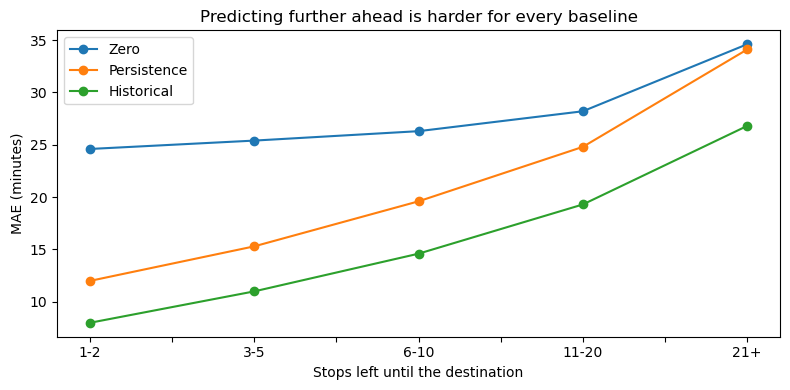

In [5]:
ax = by_stops.plot(marker="o", figsize=(8, 4))
ax.set_title("Predicting further ahead is harder for every baseline")
ax.set_xlabel("Stops left until the destination")
ax.set_ylabel("MAE (minutes)")
plt.tight_layout()
plt.savefig(FIGURES / "baselines_by_stops_left.png", dpi=120)
plt.show()

Makes sense: 1–2 stops before the end, the delay won't change much more. With 21+ stops to go, almost anything can still happen.

## Summary
| Baseline | Valid MAE |
|---|---|
| Zero | ≈ 28.8 |
| Persistence | ≈ 23.6 |
| **Historical** | **≈ 18.0 ← the bar to beat** |

**Next:** notebook 06 trains ML models and tries to beat 18.0.

### 🧠 Try it yourself
1. Add a 4th baseline: **"persistence, but 0 if only 1–2 stops are left"** (padding absorbs the rest). Does it beat persistence? Does it beat historical?
2. Compute the metrics for `hist_train_dest` alone as a prediction (this train's usual destination delay, ignoring the current delay). Why is it so much worse?
3. In one sentence, explain to a non-technical friend why *within 10 min* makes the Zero baseline look good.